# Quy luật hành vi mua cho generator — ước lượng mô hình từ dữ liệu tham chiếu

**Mục tiêu:** thay các bảng tần suất chép tay bằng **mô hình có tham số**, ước lượng từ dữ liệu, có kiểm định độ khớp và kiểm chứng ngoài mẫu/mô phỏng. Mỗi quy luật kết thúc bằng tham số đưa vào `generator/configs/small.yml`.

Mỗi mục theo trình tự: **câu hỏi → cohort → mô hình ứng viên → ước lượng → độ khớp → kiểm chứng → quy luật**. Tiêu chí chọn mô hình: AIC/log-likelihood, sai lệch tuyệt đối theo điểm phần trăm, và khả năng tái tạo thống kê mục tiêu khi mô phỏng. Với mẫu hàng triệu dòng, p-value χ² gần như luôn bằng 0; vì vậy độ khớp được đọc qua **độ lớn sai lệch**, không qua p-value.

| Nguồn | Cohort | Dùng cho |
|---|---|---|
| H&M | Kênh online (`sales_channel_id = 2`), năm 2019 | Tần suất mua, khoảng mua lại, độ phổ biến sản phẩm, giỏ hàng, lịch |
| Olist | Đơn đặt năm 2017 | Lịch (đối chiếu), giờ mua, thời gian giao, điểm đánh giá |
| eCommerce Behavior | Sự kiện `purchase`, 10–11/2019 | Đối chiếu lịch và giờ mua |

**Đã loại khỏi bản này:** UCI Online Retail (bán sỉ, không điều khiển generator; H&M thay thế cho phần mua lại), phân tích phương thức thanh toán Olist (thẻ tín dụng Brazil không chuyển được sang COD Việt Nam) và funnel phiên truy cập (không có bảng nghiệp vụ dùng kết quả).

**Nguyên tắc chuyển nguồn:** chỉ chuyển **dạng quy luật** khi nó lặp lại giữa các nguồn hoặc kiểm chứng được ngoài mẫu. Hằng số gắn với thị trường (mùa vụ châu Âu, thời gian giao ở Brazil) không chuyển; tham số Việt Nam chưa có dữ liệu được ghi rõ là giả định.

In [1]:
%matplotlib inline
import datetime as dt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import optimize, special, stats
from statsmodels.miscmodels.ordinal_model import OrderedModel

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent.parent
data_dir = repo_root / "data" / "generator" / "eda" / "raw"
rng = np.random.default_rng(20260724)
plt.rcParams["figure.figsize"] = (10, 3.6)

## 0. Dữ liệu và cohort

H&M: một dòng là một đơn vị sản phẩm đã mua; `product_code` là 7 ký tự đầu của `article_id` (article = product + màu). H&M không có mã đơn, nên **một giỏ = một khách × một ngày** trên kênh online. `customer_id` được băm thành số nguyên 64 bit để giảm bộ nhớ; phép băm chỉ dùng để nhóm.

In [2]:
hm = (
    pl.scan_csv(
        data_dir / "hm" / "transactions_train.csv",
        schema_overrides={"article_id": pl.Utf8, "customer_id": pl.Utf8, "t_dat": pl.Utf8},
    )
    .with_columns(pl.col("t_dat").str.to_date())
    .filter((pl.col("t_dat").dt.year() == 2019) & (pl.col("sales_channel_id") == 2))
    .select(
        pl.col("customer_id").hash().alias("customer"),
        "t_dat",
        "article_id",
        pl.col("article_id").str.slice(0, 7).alias("product_code"),
        "price",
    )
    .collect(engine="streaming")
)
hm.select("t_dat", "price").describe()

statistic,t_dat,price
str,str,f64
"""count""","""11397400""",1.13974e7
"""null_count""","""0""",0.0
"""mean""","""2019-06-25 17:33:00.866092""",0.029942
"""std""",null,0.020498
"""min""","""2019-01-01""",0.000017
"""25%""","""2019-04-06""",0.016932
"""50%""","""2019-06-24""",0.025407
"""75%""","""2019-09-16""",0.033881
"""max""","""2019-12-31""",0.50678


In [3]:
hm.null_count()

customer,t_dat,article_id,product_code,price
u32,u32,u32,u32,u32
0,0,0,0,0


**Nhận xét:** cohort phủ trọn 01/01–31/12/2019, không thiếu giá trị ở các cột dùng. Giá giữ thang chuẩn hóa của nguồn; không suy ra giá VND.

In [4]:
articles = (
    pl.read_csv(data_dir / "hm" / "articles.csv", schema_overrides={"article_id": pl.Utf8, "product_code": pl.Utf8})
    .select("product_code", "index_group_name", "product_group_name", "product_type_name")
    .unique("product_code")
)

olist_orders = pl.read_csv(data_dir / "olist" / "olist_orders_dataset.csv").with_columns(
    pl.col("order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date").str.to_datetime(
        strict=False
    )
).filter(pl.col("order_purchase_timestamp").dt.year() == 2017)

# eCommerce Behavior lưu UTC; cửa hàng hoạt động theo giờ Moskva (UTC+3). Một phiên mua = một đơn.
ecb = (
    pl.concat(
        [
            pl.scan_csv(
                data_dir / "ecommerce_behavior" / f"2019-{month}.csv",
                schema_overrides={"user_session": pl.Utf8, "category_code": pl.Utf8, "brand": pl.Utf8},
            ).filter(pl.col("event_type") == "purchase")
            for month in ("Oct", "Nov")
        ]
    )
    .select("user_session", "event_time")
    .unique("user_session")
    .with_columns(ts=pl.col("event_time").str.replace(" UTC", "").str.to_datetime() + pl.duration(hours=3))
    .filter(pl.col("ts").dt.date() < dt.date(2019, 12, 1))
    .collect(engine="streaming")
)
pl.DataFrame(
    {
        "source": ["H&M online 2019", "Olist 2017", "eCommerce purchases"],
        "rows": [hm.height, olist_orders.height, ecb.height],
    }
)

source,rows
str,i64
"""H&M online 2019""",11397400
"""Olist 2017""",45101
"""eCommerce purchases""",1402222


## 1. Tần suất mua của khách

**Câu hỏi:** trong một cửa sổ T, khách đã mua có bao nhiêu ngày mua? Quy luật có co giãn theo độ dài lịch sử không?

**Mô hình:** NBD của Ehrenberg — mỗi khách mua theo Poisson(λT), λ khác nhau giữa khách theo Gamma(r, α). Chỉ quan sát khách có ít nhất một lần mua, nên dùng **NBD cắt bỏ 0 (ZT-NBD)**. Đối chứng: ZT-Poisson (mọi khách cùng tốc độ). Khi r → 0, ZT-NBD hội tụ về **phân phối log-series của Fisher**: P(k) = −θᵏ / (k·ln(1−θ)), với θ = T/(α+T).

In [5]:
purchase_days = hm.select("customer", "t_dat").unique()


def customer_days(start, end):
    return (
        purchase_days.filter(pl.col("t_dat").is_between(start, end, closed="left"))
        .group_by("customer")
        .len()["len"]
        .to_numpy()
    )


def fit_zt_nbd(x, T=1.0):
    def nll(params):
        r, alpha = np.exp(params)
        log_p = (
            special.gammaln(r + x) - special.gammaln(r) - special.gammaln(x + 1)
            + r * np.log(alpha / (alpha + T)) + x * np.log(T / (alpha + T))
        )
        return -(log_p - np.log1p(-(alpha / (alpha + T)) ** r)).sum()

    result = optimize.minimize(nll, [0.0, 0.0], method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 4000})
    return *np.exp(result.x), -result.fun


def fit_zt_poisson(x):
    lam = optimize.brentq(lambda value: value / (1 - np.exp(-value)) - x.mean(), 1e-9, 1e3)
    return lam, (x * np.log(lam) - lam - special.gammaln(x + 1) - np.log1p(-np.exp(-lam))).sum()


def fit_log_series(x):
    nll = lambda t: -(x * np.log(t) - np.log(x) - np.log(-np.log1p(-t))).sum()
    theta = optimize.minimize_scalar(nll, bounds=(1e-9, 1 - 1e-9), method="bounded").x
    return theta, -nll(theta)


def log_series_pmf(k, theta):
    return -(theta**k) / (k * np.log1p(-theta))


x12 = customer_days(dt.date(2019, 1, 1), dt.date(2020, 1, 1))
r, alpha, ll_nbd = fit_zt_nbd(x12)
lam, ll_poisson = fit_zt_poisson(x12)
theta12, ll_ls = fit_log_series(x12)
pl.DataFrame(
    {
        "model": ["ZT-Poisson", "ZT-NBD", "Log-series"],
        "parameters": [f"lambda={lam:.3f}", f"r={r:.4f}, alpha={alpha:.4f}", f"theta={theta12:.4f}"],
        "AIC": [2 - 2 * ll_poisson, 4 - 2 * ll_nbd, 2 - 2 * ll_ls],
    }
).with_columns(pl.col("AIC").round(0)).insert_column(0, pl.Series("customers", [len(x12)] * 3))

customers,model,parameters,AIC
i64,str,str,f64
751398,"""ZT-Poisson""","""lambda=3.457""",4.78958e6
751398,"""ZT-NBD""","""r=0.0000, alpha=0.1292""",3.038953e6
751398,"""Log-series""","""theta=0.8855""",3.038951e6


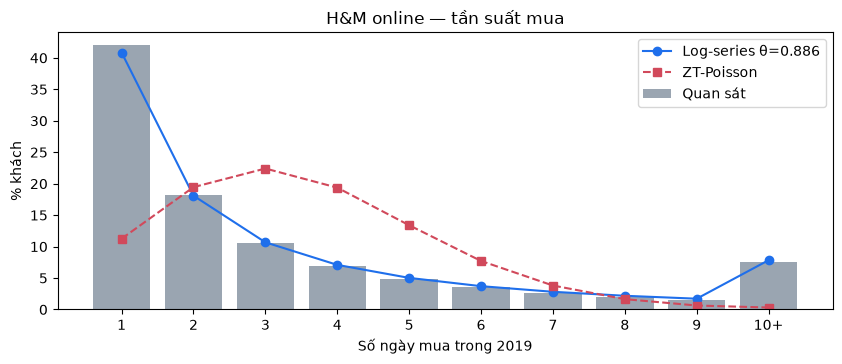

Sai lệch tuyệt đối lớn nhất (điểm %): log-series 1.1199999999999999 | Poisson 30.72


In [6]:
k = np.arange(1, 11)
observed = np.array([(x12 == i).mean() for i in k[:-1]] + [(x12 >= 10).mean()])
fitted_ls = np.append(log_series_pmf(k[:-1], theta12), 1 - log_series_pmf(k[:-1], theta12).sum())
fitted_poisson = stats.poisson.pmf(k, lam) / (1 - np.exp(-lam))
fitted_poisson[-1] = 1 - fitted_poisson[:-1].sum()
labels = [str(i) for i in k[:-1]] + ["10+"]
fig, ax = plt.subplots()
ax.bar(labels, observed * 100, color="#9aa5b1", label="Quan sát")
ax.plot(labels, fitted_ls * 100, "o-", color="#1f6feb", label=f"Log-series θ={theta12:.3f}")
ax.plot(labels, fitted_poisson * 100, "s--", color="#d1495b", label="ZT-Poisson")
ax.set(xlabel="Số ngày mua trong 2019", ylabel="% khách", title="H&M online — tần suất mua")
ax.legend()
plt.show()
print("Sai lệch tuyệt đối lớn nhất (điểm %): log-series", np.abs(observed - fitted_ls).max().round(4) * 100,
      "| Poisson", np.abs(observed - fitted_poisson).max().round(4) * 100)

**Nhận xét:** ZT-Poisson sai hoàn toàn: nó dự báo đỉnh ở 3–4 lần mua, còn thực tế 42% khách chỉ mua một lần. ZT-NBD đưa ước lượng r về biên 0, nên mô hình còn lại là log-series một tham số, với AIC gần như bằng NBD. Sai lệch lớn nhất khoảng 1,1 điểm %, nằm ở nhóm mua một lần. Như vậy **sự khác biệt giữa các khách** quyết định phân phối, chứ không phải ba nhãn phân khúc cố định.

### 1.1. Kiểm chứng ngoài mẫu: quy luật co giãn theo cửa sổ

Nếu NBD đúng, θ phụ thuộc độ dài cửa sổ theo θ(T) = T/(α+T) với **cùng một α**. Ước lượng α trên cửa sổ 6 tháng, rồi dự báo θ cho 3 và 12 tháng mà không fit lại.

In [7]:
windows = {"3 tháng": (dt.date(2019, 1, 1), dt.date(2019, 4, 1), 0.25),
           "6 tháng": (dt.date(2019, 1, 1), dt.date(2019, 7, 1), 0.5),
           "12 tháng": (dt.date(2019, 1, 1), dt.date(2020, 1, 1), 1.0)}
fits = {name: (fit_log_series(customer_days(start, end))[0], T) for name, (start, end, T) in windows.items()}
alpha_6m = 0.5 * (1 - fits["6 tháng"][0]) / fits["6 tháng"][0]
pl.DataFrame(
    {
        "window": list(fits),
        "theta_fit": [theta for theta, _ in fits.values()],
        "theta_predicted_from_6m": [T / (alpha_6m + T) for _, T in fits.values()],
    }
).with_columns(pl.col("theta_fit", "theta_predicted_from_6m").round(4))

window,theta_fit,theta_predicted_from_6m
str,f64,f64
"""3 tháng""",0.7021,0.6865
"""6 tháng""",0.8141,0.8141
"""12 tháng""",0.8855,0.8975


**Nhận xét:** từ một α ≈ 0,114 năm (ước lượng trên 6 tháng), công thức dự báo θ cho 12 tháng là 0,898 so với fit 0,886, và cho 3 tháng là 0,687 so với 0,702. Đây là kiểm chứng ngoài mẫu: cùng một tham số giải thích được ba độ dài lịch sử.

**Quy luật R01:** số đơn của một khách đã mua trong T năm theo phân phối **log-series với θ = T/(α+T), α = 0,114 năm**. Generator đọc `history_months`, tự tính θ, và tổng số đơn là **kết quả** của mô hình chứ không còn là đầu vào.

## 2. Khoảng cách giữa các lần mua

**Câu hỏi:** với khách mua k lần, các lần mua cách nhau thế nào? Chọn ngày độc lập theo lịch có đủ không?

**Mô hình:** NBD giả định mỗi khách là một tiến trình Poisson, nên khoảng cách theo phân phối mũ (Weibull với shape = 1, hệ số biến thiên CV = 1). Kiểm tra shape và CV theo từng k.

In [8]:
gaps = (
    purchase_days.sort("customer", "t_dat")
    .with_columns(
        gap=(pl.col("t_dat") - pl.col("t_dat").shift(1).over("customer")).dt.total_days(),
        k=pl.len().over("customer"),
    )
    .filter(pl.col("gap").is_not_null())
)
rows = []
for k_value in (2, 3, 4, 5, 6, 8, 10, 15, 20):
    g = gaps.filter(pl.col("k") == k_value)["gap"].to_numpy().astype(float)
    shape, _, scale = stats.weibull_min.fit(g, floc=0)
    rows.append({"k": k_value, "gaps": len(g), "median": np.median(g), "mean": g.mean(), "cv": g.std() / g.mean(),
                 "weibull_shape": shape, "uniform_mean_365/(k+1)": 365 / (k_value + 1)})
gap_table = pl.DataFrame(rows).with_columns(pl.exclude("k", "gaps").round(3))
gap_table

k,gaps,median,mean,cv,weibull_shape,uniform_mean_365/(k+1)
i64,i64,f64,f64,f64,f64,f64
2,136873,67.0,90.188,0.932,0.874,121.667
3,158502,57.0,75.272,0.929,0.924,91.25
4,157062,48.0,63.794,0.931,0.953,73.0
5,147124,40.0,54.613,0.944,0.962,60.833
6,134140,35.0,47.879,0.946,0.977,52.143
8,108416,28.0,38.138,0.968,0.983,40.556
10,85986,22.0,31.371,0.983,0.988,33.182
15,46620,15.0,21.922,1.013,1.006,22.812
20,27170,11.0,16.743,1.047,1.008,17.381


**Nhận xét:** shape từ 0,87 (k = 2) đến 1,01 (k = 20) và CV ≈ 0,93–1,05, nên khoảng cách gần như theo phân phối mũ, đúng với giả định Poisson. Điểm lệch là **trung bình nhỏ hơn 365/(k+1)** ở khách mua ít lần. Lý do là khách không hoạt động trọn năm (mới đến hoặc rời đi giữa năm), nên các lần mua dồn vào một khoảng ngắn hơn.

c = 0.517; sai số tương đối lớn nhất k=2..30: 0.019


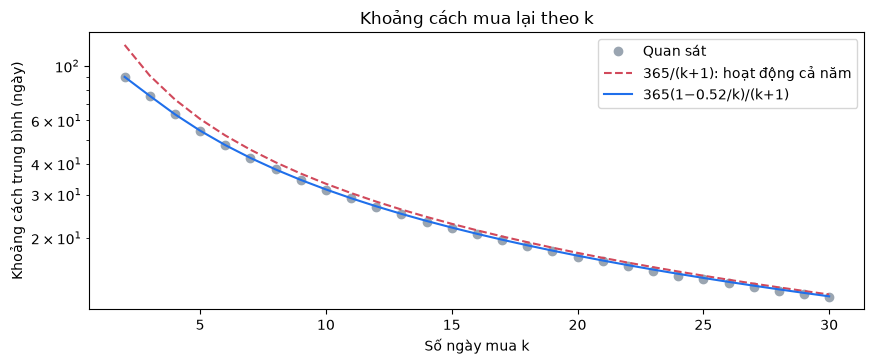

In [9]:
by_k = gaps.filter(pl.col("k") <= 30).group_by("k").agg(mean=pl.col("gap").mean(), n=pl.len()).sort("k")
k_values, mean_gap, weight = (by_k[c].to_numpy() for c in ("k", "mean", "n"))
gap_mean = lambda k_value, c: 365 * (1 - c / k_value) / (k_value + 1)
(shrink,), _ = optimize.curve_fit(gap_mean, k_values, mean_gap, p0=[0.5], sigma=1 / np.sqrt(weight))
print(f"c = {shrink:.3f}; sai số tương đối lớn nhất k=2..30: {np.max(np.abs(gap_mean(k_values, shrink) / mean_gap - 1)):.3f}")
fig, ax = plt.subplots()
ax.plot(k_values, mean_gap, "o", color="#9aa5b1", label="Quan sát")
ax.plot(k_values, 365 / (k_values + 1), "--", color="#d1495b", label="365/(k+1): hoạt động cả năm")
ax.plot(k_values, gap_mean(k_values, shrink), "-", color="#1f6feb", label=f"365(1−{shrink:.2f}/k)/(k+1)")
ax.set(xlabel="Số ngày mua k", ylabel="Khoảng cách trung bình (ngày)", yscale="log", title="Khoảng cách mua lại theo k")
ax.legend()
plt.show()

### 2.1. Kiểm chứng bằng mô phỏng

Mô phỏng: lấy k từ log-series(θ = 0,886); với k ≥ 2, lấy k − 1 khoảng cách mũ có trung bình μ_k = T(1 − c/k)/(k+1), làm tròn thành ngày (tối thiểu 1); bỏ chuỗi vượt cửa sổ. So sánh với dữ liệu thật và với cách chọn ngày độc lập theo lịch.

In [10]:
def simulate_gaps(theta, c, T=365, customers=300_000):
    sampled_k = stats.logser.rvs(theta, size=customers, random_state=rng)
    simulated, simulated_k = [], []
    for k_value in sampled_k[sampled_k >= 2]:
        mu = T * (1 - c / k_value) / (k_value + 1)
        for _ in range(20):
            g = np.maximum(1, np.round(rng.exponential(mu, k_value - 1)))
            if g.sum() <= T - 1:
                simulated.extend(g)
                simulated_k.extend([k_value] * (k_value - 1))
                break
    return np.array(simulated), np.array(simulated_k)


simulated, simulated_k = simulate_gaps(theta12, shrink)
observed_gaps, observed_k = gaps["gap"].to_numpy(), gaps["k"].to_numpy()
calendar = purchase_days.group_by("t_dat").len().sort("t_dat")["len"].to_numpy()
independent = np.abs(np.diff(rng.choice(len(calendar), size=(200_000, 2), p=calendar / calendar.sum()), axis=1)).ravel()
independent = independent[independent > 0]
check = [{"k": "tất cả", "observed_median": np.median(observed_gaps), "model_median": np.median(simulated),
          "KS_model": stats.ks_2samp(observed_gaps, simulated).statistic}]
for k_value in (2, 3, 5, 10, 20):
    a, b = observed_gaps[observed_k == k_value], simulated[simulated_k == k_value]
    check.append({"k": str(k_value), "observed_median": np.median(a), "model_median": np.median(b),
                  "KS_model": stats.ks_2samp(a, b).statistic})
check.append({"k": "2 (chọn ngày độc lập)", "observed_median": np.median(observed_gaps[observed_k == 2]),
              "model_median": np.median(independent),
              "KS_model": stats.ks_2samp(observed_gaps[observed_k == 2], independent).statistic})
pl.DataFrame(check).with_columns(pl.col("KS_model").round(3))

k,observed_median,model_median,KS_model
str,f64,f64,f64
"""tất cả""",21.0,22.0,0.051
"""2""",67.0,61.0,0.1
"""3""",57.0,50.0,0.074
"""5""",40.0,34.0,0.071
"""10""",22.0,20.0,0.056
"""20""",11.0,11.0,0.032
"""2 (chọn ngày độc lập)""",67.0,106.0,0.177


**Nhận xét:** mô hình tái tạo phân phối khoảng cách gộp với KS ≈ 0,05. Với k = 2, KS của mô hình là 0,10, còn cách chọn ngày độc lập là 0,18 (trung vị thực tế 67 ngày, cách cũ cho 105). Mô hình vẫn hơi ngắn ở k nhỏ vì phân phối mũ có trung vị bằng 0,69 lần trung bình, trong khi thực tế là 0,74. Mức lệch này được chấp nhận.

**Quy luật R02:** khoảng cách giữa hai lần mua liên tiếp của khách có k lần mua theo **phân phối mũ, trung bình μ_k = T·(1 − c/k)/(k+1), c = 0,517**. Lần mua đầu chọn theo cường độ lịch (mục 5).

## 3. Độ phổ biến sản phẩm

**Câu hỏi:** nhu cầu phân bố giữa các sản phẩm theo quy luật nào để áp được cho catalog 60 hay 200 sản phẩm?

**Cohort:** product_code thuộc Ladieswear/Divided (shop của dự án bán thời trang nữ), kênh online 2019.

**Mô hình:** (a) Zipf, tức số bán ∝ hạng^(−s); (b) log-normal, tức log(số bán) ~ N(μ, σ). Với log-normal chỉ σ quyết định mức tập trung, nên **có thể áp cho catalog cỡ bất kỳ** bằng cách lấy mẫu trọng số cho từng sản phẩm.

products=17998; Zipf slope toàn bộ=1.85, đoạn giữa=1.15


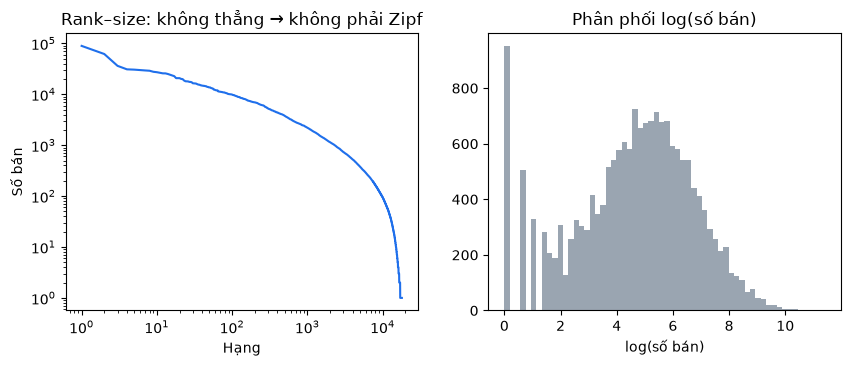

In [11]:
product_sales = (
    hm.group_by("product_code")
    .agg(units=pl.len(), months=pl.col("t_dat").dt.month().n_unique(), price=pl.col("price").median())
    .join(articles, on="product_code")
    .filter(pl.col("index_group_name").is_in(["Ladieswear", "Divided"]))
)
units = np.sort(product_sales["units"].to_numpy())[::-1]
rank = np.arange(1, len(units) + 1)
slope_all = -np.polyfit(np.log(rank), np.log(units), 1)[0]
middle = slice(len(units) // 100, len(units) // 2)
slope_middle = -np.polyfit(np.log(rank[middle]), np.log(units[middle]), 1)[0]
print(f"products={len(units)}; Zipf slope toàn bộ={slope_all:.2f}, đoạn giữa={slope_middle:.2f}")
fig, ax = plt.subplots(1, 2)
ax[0].loglog(rank, units, color="#1f6feb")
ax[0].set(xlabel="Hạng", ylabel="Số bán", title="Rank–size: không thẳng → không phải Zipf")
ax[1].hist(np.log(units), bins=60, color="#9aa5b1")
ax[1].set(xlabel="log(số bán)", title="Phân phối log(số bán)")
plt.show()

**Nhận xét:** đường rank–size bị cong. Độ dốc Zipf đổi từ 1,15 (đoạn giữa) lên 1,85 (toàn bộ), nên không có một số mũ duy nhất và loại Zipf. Histogram log(số bán) có đuôi trái dày, đến từ những sản phẩm bán rất ít.

### 3.1. Kiểm soát thời gian bày bán

Sản phẩm ra mắt hoặc ngừng bán giữa năm có số bán thấp vì **bày bán ít ngày hơn**, không phải vì kém phổ biến. Catalog của generator bán suốt lịch sử, nên tham số phải đo trên sản phẩm có bán trong **cả 12 tháng**. Ước lượng σ bằng hai cách độc lập: MLE trên log(số bán), và khớp đường cong Lorenz L(p) = Φ(Φ⁻¹(p) − σ), vốn là thống kê quyết định tỷ trọng doanh số.

In [12]:
def lorenz_sigma(x):
    xs = np.sort(x)
    p = np.linspace(0.01, 0.99, 99)
    empirical = np.interp(p, np.arange(1, len(xs) + 1) / len(xs), np.cumsum(xs) / xs.sum())
    loss = lambda sigma: ((stats.norm.cdf(stats.norm.ppf(p) - sigma) - empirical) ** 2).sum()
    return optimize.minimize_scalar(loss, bounds=(0.1, 4), method="bounded").x


def top_share(weights, fraction):
    w = np.sort(weights)[::-1]
    return w[: max(1, int(len(w) * fraction))].sum() / w.sum()


rows = []
for label, frame in (("Tất cả sản phẩm", product_sales), ("Bán đủ 12 tháng", product_sales.filter(pl.col("months") == 12))):
    x = frame["units"].to_numpy()
    log_x = np.log(x)
    rows.append({"cohort": label, "products": len(x), "sigma_mle": log_x.std(), "sigma_lorenz": lorenz_sigma(x),
                 "skew_log": stats.skew(log_x), "KS_lognormal": stats.kstest(log_x, "norm", args=(log_x.mean(), log_x.std())).statistic})
pl.DataFrame(rows).with_columns(pl.exclude("cohort", "products").round(3))

cohort,products,sigma_mle,sigma_lorenz,skew_log,KS_lognormal
str,i64,f64,f64,f64,f64
"""Tất cả sản phẩm""",17998,2.156,1.702,-0.361,0.053
"""Bán đủ 12 tháng""",2095,1.35,1.408,0.257,0.028


In [13]:
full_year = product_sales.filter(pl.col("months") == 12)["units"].to_numpy()
sigma_popularity = lorenz_sigma(full_year)
rows = []
for n in (60, 200):
    model = [[top_share(rng.lognormal(0, sigma_popularity, n), f) for f in (0.1, 0.2)] for _ in range(500)]
    empirical = [[top_share(rng.choice(full_year, n, replace=False), f) for f in (0.1, 0.2)] for _ in range(500)]
    rows.append({"catalog": n, "top10_model": np.mean(model, axis=0)[0], "top10_hm": np.mean(empirical, axis=0)[0],
                 "top20_model": np.mean(model, axis=0)[1], "top20_hm": np.mean(empirical, axis=0)[1]})
pl.DataFrame(rows).with_columns(pl.exclude("catalog").round(3))

catalog,top10_model,top10_hm,top20_model,top20_hm
i64,f64,f64,f64,f64
60,0.515,0.526,0.69,0.699
200,0.538,0.546,0.709,0.713


**Nhận xét:** khi bỏ ảnh hưởng của thời gian bày bán, log-normal khớp tốt (KS ≈ 0,03, độ lệch nhỏ), và hai cách ước lượng gần trùng nhau (MLE 1,35, Lorenz 1,41). Lấy mẫu σ = 1,41 cho catalog 60 hoặc 200 sản phẩm tái tạo được tỷ trọng top 10% và top 20% của H&M, sai lệch dưới 1 điểm %. Nếu dùng toàn bộ sản phẩm, σ ước lượng bằng MLE (2,16) làm phóng đại mức tập trung, và cách sửa đúng là đo trên sản phẩm bán đủ năm.

**Quy luật R03:** trọng số nhu cầu của mỗi sản phẩm **w ~ LogNormal(0, σ = 1,41)**, lấy độc lập cho từng sản phẩm.

### 3.2. Giá và nhóm hàng có làm thay đổi nhu cầu không?

In [14]:
print("Spearman(giá, số bán):", round(stats.spearmanr(product_sales["price"], product_sales["units"]).statistic, 3))

CATEGORY_TYPES = {
    "ao": ["Sweater", "Blouse", "Top", "T-shirt", "Vest top", "Shirt", "Cardigan", "Hoodie", "Bodysuit", "Polo shirt"],
    "khoac": ["Jacket", "Blazer", "Coat", "Outdoor Waistcoat", "Tailored Waistcoat"],
    "dam": ["Dress", "Jumpsuit/Playsuit", "Dungarees"],
    "vay": ["Skirt"],
    "quan": ["Trousers", "Shorts", "Leggings/Tights", "Outdoor trousers"],
    "tui-xach": ["Bag", "Weekend/Gym bag", "Shoulder bag", "Wallet"],
}
category = pl.when(pl.col("product_group_name") == "Shoes").then(pl.lit("giay"))
for code_name, types in CATEGORY_TYPES.items():
    category = category.when(pl.col("product_type_name").is_in(types)).then(pl.lit(code_name))
category = category.when(
    (pl.col("product_group_name") == "Accessories")
    & ~pl.col("product_type_name").is_in(["Dog Wear", "Giftbox", "Waterbottle", "Umbrella"])
).then(pl.lit("phu-kien"))
categorized = product_sales.with_columns(category=category)
print("Tỷ trọng số bán ngoài 8 nhóm (đồ bơi, đồ lót, đồ ngủ, tất...):",
      round(categorized.filter(pl.col("category").is_null())["units"].sum() / categorized["units"].sum(), 3))
categorized = categorized.filter(pl.col("category").is_not_null())
category_table = (
    categorized.group_by("category")
    .agg(products=pl.len(), units=pl.col("units").sum())
    .with_columns(product_share=pl.col("products") / pl.col("products").sum(), demand_share=pl.col("units") / pl.col("units").sum())
    .with_columns(demand_multiplier=pl.col("demand_share") / pl.col("product_share"))
    .sort("demand_share", descending=True)
)
print("Kruskal–Wallis số bán theo nhóm, p =", stats.kruskal(*[g["units"].to_numpy() for _, g in categorized.group_by("category")]).pvalue)
category_table.with_columns(pl.col("product_share", "demand_share", "demand_multiplier").round(3))

Spearman(giá, số bán): 0.012
Tỷ trọng số bán ngoài 8 nhóm (đồ bơi, đồ lót, đồ ngủ, tất...): 0.204
Kruskal–Wallis số bán theo nhóm, p = 3.040577622858726e-73


category,products,units,product_share,demand_share,demand_multiplier
str,u32,u32,f64,f64,f64
"""ao""",5501,3354663,0.349,0.415,1.19
"""quan""",2134,1884214,0.135,0.233,1.723
"""dam""",3082,1401084,0.195,0.173,0.887
"""khoac""",1195,401862,0.076,0.05,0.656
"""vay""",897,373932,0.057,0.046,0.814
"""giay""",827,306829,0.052,0.038,0.724
"""phu-kien""",1754,282852,0.111,0.035,0.315
"""tui-xach""",384,75861,0.024,0.009,0.386


**Nhận xét:** tương quan giữa giá và số bán gần bằng 0 (ρ ≈ 0,01), nên **không cần ràng buộc giá với độ phổ biến**. Nhóm hàng thì có ảnh hưởng (Kruskal–Wallis p ≈ 0): quần bán 1,7 lần mức trung bình mỗi sản phẩm, còn phụ kiện chỉ 0,3 lần. Generator dùng `product_share` để chia số sản phẩm theo nhóm và `demand_multiplier` để nhân vào trọng số log-normal. Việc ánh xạ product_type của H&M sang 8 nhóm của shop là giả định; 20% số bán thuộc các nhóm shop không kinh doanh nên bị loại.

## 4. Giỏ hàng

**Câu hỏi:** một đơn có bao nhiêu sản phẩm, bao nhiêu biến thể của cùng một sản phẩm, và bao nhiêu đơn vị mỗi biến thể?

**Cohort:** H&M online, giỏ = khách × ngày. Article tương ứng với biến thể (product + màu). Mô hình ứng viên: ZT-Poisson, hình học dịch 1, ZT-NBD và log-series.

In [15]:
lines = hm.group_by("customer", "t_dat", "product_code", "article_id").agg(quantity=pl.len())
baskets = lines.group_by("customer", "t_dat").agg(products=pl.col("product_code").n_unique())
variants_per_product = lines.group_by("customer", "t_dat", "product_code").agg(variants=pl.len())["variants"].to_numpy()
quantity = lines["quantity"].to_numpy()


def fit_zt_nbd_mean(x):
    def nll(params):
        r_value, m = np.exp(params)
        p = r_value / (r_value + m)
        log_p = special.gammaln(r_value + x) - special.gammaln(r_value) - special.gammaln(x + 1) + r_value * np.log(p) + x * np.log1p(-p)
        return -(log_p - np.log1p(-(p**r_value))).sum()

    result = optimize.minimize(nll, [0.0, 0.0], method="Nelder-Mead")
    return *np.exp(result.x), -result.fun


def zt_nbd_pmf(k, r_value, m):
    p = r_value / (r_value + m)
    return np.exp(special.gammaln(r_value + k) - special.gammaln(r_value) - special.gammaln(k + 1) + r_value * np.log(p) + k * np.log1p(-p)) / (1 - p**r_value)


rows = []
for label, x in (("sản phẩm / giỏ", baskets["products"].to_numpy()), ("biến thể / sản phẩm", variants_per_product), ("đơn vị / biến thể", quantity)):
    x = x.astype(float)
    r_value, m, ll_nbd = fit_zt_nbd_mean(x)
    theta, ll_ls = fit_log_series(x)
    _, ll_p = fit_zt_poisson(x)
    p_geo = 1 / x.mean()
    ll_geo = (np.log(p_geo) + (x - 1) * np.log1p(-p_geo)).sum()
    rows.append({"variable": label, "n": len(x), "mean": x.mean(), "share_1": (x == 1).mean(),
                 "AIC_poisson": 2 - 2 * ll_p, "AIC_geometric": 2 - 2 * ll_geo, "AIC_log_series": 2 - 2 * ll_ls,
                 "AIC_zt_nbd": 4 - 2 * ll_nbd, "r": r_value, "m": m, "theta": theta})
basket_fits = pl.DataFrame(rows)
basket_fits.with_columns(pl.col("mean", "share_1", "r", "m", "theta").round(4), pl.col("^AIC.*$").round(0))

variable,n,mean,share_1,AIC_poisson,AIC_geometric,AIC_log_series,AIC_zt_nbd,r,m,theta
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""sản phẩm / giỏ""",2682063,3.3729,0.3124,1.3326264e7,1.099762e7,1.1152043e7,1.0974837e7,0.6485,2.0278,0.8754
"""biến thể / sản phẩm""",9046247,1.091,0.9206,5.716054e6,5.665509e6,5.646868e6,5.64687e6,0.0,0.0,0.1578
"""đơn vị / biến thể""",9869468,1.1548,0.8693,9.156747e6,8.981878e6,8.950669e6,8.950671e6,0.0,0.0,0.2452


In [16]:
basket_r, basket_m = basket_fits.row(0, named=True)["r"], basket_fits.row(0, named=True)["m"]
theta_variants, theta_quantity = basket_fits["theta"][1], basket_fits["theta"][2]
k = np.arange(1, 8)
x = baskets["products"].to_numpy()
comparison = pl.DataFrame({
    "k": k,
    "products_observed_%": [(x == i).mean() * 100 for i in k],
    "products_zt_nbd_%": zt_nbd_pmf(k, basket_r, basket_m) * 100,
    "variants_observed_%": [(variants_per_product == i).mean() * 100 for i in k],
    "variants_log_series_%": log_series_pmf(k, theta_variants) * 100,
    "quantity_observed_%": [(quantity == i).mean() * 100 for i in k],
    "quantity_log_series_%": log_series_pmf(k, theta_quantity) * 100,
}).with_columns(pl.exclude("k").round(2))
customer_frequency = baskets.join(baskets.group_by("customer").len(), on="customer")
print("Spearman(số sản phẩm/giỏ, số ngày mua của khách):",
      round(stats.spearmanr(customer_frequency["products"], customer_frequency["len"]).statistic, 3))
comparison

Spearman(số sản phẩm/giỏ, số ngày mua của khách): 0.016


k,products_observed_%,products_zt_nbd_%,variants_observed_%,variants_log_series_%,quantity_observed_%,quantity_log_series_%
i64,f64,f64,f64,f64,f64,f64
1,31.24,32.6,92.06,91.88,86.93,87.17
2,22.23,20.36,6.99,7.25,11.64,10.69
3,14.11,13.62,0.79,0.76,0.95,1.75
4,9.52,9.41,0.13,0.09,0.32,0.32
5,6.37,6.63,0.03,0.01,0.05,0.06
6,4.48,4.73,0.01,0.0,0.05,0.01
7,3.13,3.4,0.0,0.0,0.01,0.0


**Nhận xét:**
- **Số sản phẩm mỗi giỏ:** ZT-NBD có AIC tốt nhất (r ≈ 0,65, m ≈ 2,03; trung bình 3,4 sản phẩm), sai lệch theo từng k dưới 2 điểm %.
- **Số biến thể của cùng sản phẩm và số đơn vị mỗi biến thể:** NBD về biên r → 0, tức log-series, với θ ≈ 0,16 và 0,26; 92% và 87% bằng 1.
- **Độc lập với khách:** kích thước giỏ gần như không phụ thuộc tần suất mua của khách (ρ ≈ 0,02), nên lấy mẫu giỏ độc lập với khách là hợp lệ.

**Giới hạn chuyển nguồn:** giỏ H&M (thương hiệu thời trang, gộp theo ngày) lớn hơn nhiều so với Olist 2017 (sàn thương mại, chủ yếu túi/phụ kiện, khoảng 93% đơn có một sản phẩm). Chọn H&M vì shop của dự án là shop một thương hiệu thời trang. Đây là **giả định chuyển nguồn**; thay bằng tham số Olist nếu muốn mô phỏng hành vi kiểu sàn.

**Quy luật R04:** số sản phẩm mỗi đơn theo **ZT-NBD(r = 0,65, m = 2,03)**; số biến thể của mỗi sản phẩm theo **log-series(θ_v)**; số đơn vị mỗi biến thể theo **log-series(θ_q)**.

## 5. Lịch: thứ trong tuần, sự kiện giảm giá và giờ mua

**Mô hình:** hồi quy log-tuyến tính Negative Binomial trên số đơn mỗi ngày: log μ_d = β₀ + thứ + tháng (hoặc xu hướng) + ngày Black Friday + 3 ngày sau Black Friday. Các hệ số mũ là **hệ số nhân** có khoảng tin cậy 95%. Fit riêng từng nguồn và chỉ giữ hiệu ứng lặp lại giữa các nguồn.

In [17]:
def daily(frame, date_column):
    return frame.group_by(d=pl.col(date_column)).len().sort("d").rename({"len": "n"}).to_pandas()


sources = {
    "H&M 2019": (daily(purchase_days, "t_dat"), dt.date(2019, 11, 29), "C(month)"),
    "Olist 2017": (daily(olist_orders.with_columns(day=pl.col("order_purchase_timestamp").dt.date()), "day"), dt.date(2017, 11, 24), "C(month) + t"),
    "eCommerce 10–11/2019": (daily(ecb.with_columns(day=pl.col("ts").dt.date()), "day"), dt.date(2019, 11, 29), "t"),
}
calendar_rows, dow_profiles, event_logs = [], {}, {}
for name, (frame, black_friday, seasonal) in sources.items():
    frame["d"] = pd.to_datetime(frame["d"])
    frame["dow"] = frame["d"].dt.day_of_week.astype(str)
    frame["month"] = frame["d"].dt.month.astype(str)
    frame["t"] = (frame["d"] - frame["d"].min()).dt.days / 365
    event = pd.Timestamp(black_friday)
    frame["event_day"] = (frame["d"] == event).astype(int)
    frame["after_event"] = ((frame["d"] > event) & (frame["d"] <= event + pd.Timedelta(days=3))).astype(int)
    formula = f'n ~ C(dow, Treatment("0")) + event_day + after_event + {seasonal}'
    model = smf.glm(formula, data=frame, family=sm.families.NegativeBinomial(alpha=0.05)).fit()
    dispersion = max(1e-4, (((frame["n"] - model.mu) ** 2 - model.mu) / model.mu**2).mean())
    model = smf.glm(formula, data=frame, family=sm.families.NegativeBinomial(alpha=dispersion)).fit()
    ci = model.conf_int()
    dow = np.exp([0.0] + [model.params[f'C(dow, Treatment("0"))[T.{i}]'] for i in range(1, 7)])
    dow_profiles[name] = dow / dow.mean()
    event_logs[name] = {term: (model.params[term], model.bse[term]) for term in ("event_day", "after_event")}
    calendar_rows.append({
        "source": name, "days": len(frame),
        "event_day_x": np.exp(model.params["event_day"]), "event_day_ci": f"{np.exp(ci.loc['event_day', 0]):.2f}–{np.exp(ci.loc['event_day', 1]):.2f}",
        "after_3_days_x": np.exp(model.params["after_event"]), "after_ci": f"{np.exp(ci.loc['after_event', 0]):.2f}–{np.exp(ci.loc['after_event', 1]):.2f}",
    })
pl.DataFrame(calendar_rows).with_columns(pl.col("event_day_x", "after_3_days_x").round(2))

source,days,event_day_x,event_day_ci,after_3_days_x,after_ci
str,i64,f64,str,f64,str
"""H&M 2019""",365,5.22,"""2.77–9.84""",2.51,"""1.74–3.64"""
"""Olist 2017""",361,6.48,"""3.98–10.56""",2.56,"""1.90–3.45"""
"""eCommerce 10–11/2019""",60,1.05,"""0.41–2.70""",0.82,"""0.32–2.08"""


In [18]:
def pooled(terms):
    estimates = np.array([estimate for estimate, _ in terms])
    weights = 1 / np.array([se for _, se in terms]) ** 2
    mean = (estimates * weights).sum() / weights.sum()
    se = weights.sum() ** -0.5
    return np.exp([mean, mean - 1.96 * se, mean + 1.96 * se])


fashion = ("H&M 2019", "Olist 2017")
event_multiplier = pooled([event_logs[name]["event_day"] for name in fashion])
after_multiplier = pooled([event_logs[name]["after_event"] for name in fashion])
print("Gộp H&M + Olist — ngày sự kiện: x{:.2f} (95% CI {:.2f}–{:.2f})".format(*event_multiplier))
print("Gộp H&M + Olist — 3 ngày sau: x{:.2f} (95% CI {:.2f}–{:.2f})".format(*after_multiplier))
dow_frame = pl.DataFrame({"weekday": ["T2", "T3", "T4", "T5", "T6", "T7", "CN"], **{k: np.round(v, 3) for k, v in dow_profiles.items()}})
print("Tương quan hồ sơ thứ trong tuần giữa các nguồn:")
print(np.round(np.corrcoef(np.vstack(list(dow_profiles.values()))), 2))
dow_frame

Gộp H&M + Olist — ngày sự kiện: x5.98 (95% CI 4.06–8.81)
Gộp H&M + Olist — 3 ngày sau: x2.54 (95% CI 2.02–3.20)
Tương quan hồ sơ thứ trong tuần giữa các nguồn:
[[ 1.    0.72 -0.42]
 [ 0.72  1.   -0.65]
 [-0.42 -0.65  1.  ]]


weekday,H&M 2019,Olist 2017,eCommerce 10–11/2019
str,f64,f64,f64
"""T2""",1.016,1.132,0.915
"""T3""",1.027,1.166,0.861
"""T4""",1.147,1.097,0.878
"""T5""",1.063,1.056,0.849
"""T6""",0.89,0.946,0.944
"""T7""",0.904,0.762,1.038
"""CN""",0.952,0.841,1.514


**Nhận xét:**
- **Ngày giảm giá lớn:** Black Friday tăng số đơn ×5,2 (H&M) và ×6,5 (Olist), khoảng tin cậy chồng nhau. Ba ngày sau vẫn ×2,5 ở cả hai nguồn. Gộp lại: ngày sự kiện **×6,0 (95% CI khoảng 4,1–8,8)**, đuôi sau sự kiện **×2,5**. eCommerce Behavior (đồ điện tử, Nga) không có hiệu ứng này: Black Friday không phải sự kiện của cửa hàng đó, và chỉ có 60 ngày dữ liệu.
- **Thứ trong tuần:** mỗi nguồn đạt đỉnh một ngày khác nhau (H&M thứ Tư, Olist thứ Ba, eCommerce Chủ nhật), tương quan giữa các nguồn từ −0,65 đến 0,72. **Không có quy luật chung**, nên không chuyển hình dạng; generator để hệ số thứ bằng nhau.
- **Mùa vụ theo tháng** của H&M (đỉnh tháng 6 do sale hè châu Âu) gắn với thị trường, không chuyển sang Việt Nam.

**Quy luật R05a:** ngày sale lớn nhân cường độ đặt hàng **×6,0**, ba ngày sau **×2,5**. Áp mức này cho 11.11, 12.12 và Black Friday tại Việt Nam là **giả định chuyển nguồn**. Tết và các ngày đôi nhỏ không có dữ liệu, nên ghi là giả định.

Ổn định trong nguồn (eCommerce T10 vs T11): r = 0.97
Giữa nguồn (Olist vs eCommerce, ngày thường): r = 0.692
Olist sự kiện vs thường: JS = 0.0099


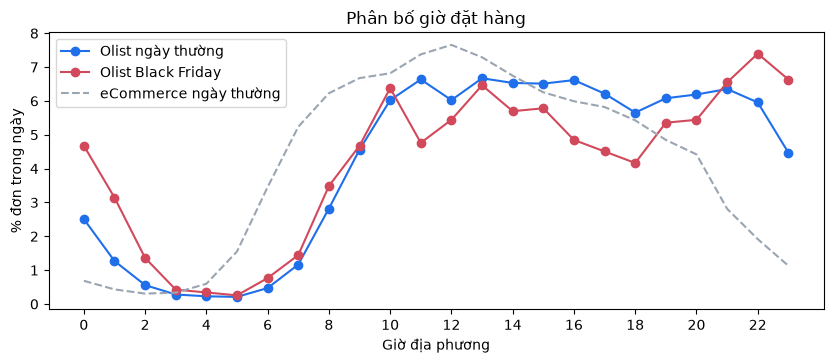

In [19]:
def hour_profile(frame, column, event_date):
    tagged = frame.with_columns(hour=pl.col(column).dt.hour(), event=pl.col(column).dt.date() == event_date)
    profiles = {}
    for label, condition in (("thường", ~pl.col("event")), ("sự kiện", pl.col("event"))):
        counts = tagged.filter(condition).group_by("hour").len().sort("hour")["len"].to_numpy()
        profiles[label] = counts / counts.sum()
    return profiles


def jensen_shannon(a, b):
    mid = (a + b) / 2
    return 0.5 * (a * np.log(a / mid)).sum() + 0.5 * (b * np.log(b / mid)).sum()


olist_hours = hour_profile(olist_orders, "order_purchase_timestamp", dt.date(2017, 11, 24))
ecb_hours = hour_profile(ecb, "ts", dt.date(2019, 11, 29))
october = ecb.filter(pl.col("ts").dt.month() == 10).group_by(h=pl.col("ts").dt.hour()).len().sort("h")["len"].to_numpy()
november = ecb.filter((pl.col("ts").dt.month() == 11) & (pl.col("ts").dt.date() != dt.date(2019, 11, 29))).group_by(h=pl.col("ts").dt.hour()).len().sort("h")["len"].to_numpy()
print("Ổn định trong nguồn (eCommerce T10 vs T11): r =", round(np.corrcoef(october, november)[0, 1], 3))
print("Giữa nguồn (Olist vs eCommerce, ngày thường): r =", round(np.corrcoef(olist_hours["thường"], ecb_hours["thường"])[0, 1], 3))
print("Olist sự kiện vs thường: JS =", round(jensen_shannon(olist_hours["thường"], olist_hours["sự kiện"]), 4))
fig, ax = plt.subplots()
ax.plot(olist_hours["thường"] * 100, "-o", color="#1f6feb", label="Olist ngày thường")
ax.plot(olist_hours["sự kiện"] * 100, "-o", color="#d1495b", label="Olist Black Friday")
ax.plot(ecb_hours["thường"] * 100, "--", color="#9aa5b1", label="eCommerce ngày thường")
ax.set(xlabel="Giờ địa phương", ylabel="% đơn trong ngày", xticks=range(0, 24, 2), title="Phân bố giờ đặt hàng")
ax.legend()
plt.show()

**Nhận xét:** phân bố giờ rất ổn định trong cùng một nguồn (r ≈ 0,97) nhưng khác giữa các nguồn (r ≈ 0,69). Olist có đơn rải đều từ 10h đến 23h. eCommerce đạt đỉnh buổi sáng–trưa (khách là doanh nghiệp và văn phòng). Vào ngày sự kiện, Olist dịch sang **nửa đêm (0–1h tăng khoảng gấp đôi) và tối muộn**, đúng với giả định "sale lúc 0h".

**Quy luật R05b:** giờ đặt hàng lấy từ phân bố Olist, với hai phân bố riêng cho ngày thường và ngày sự kiện. Chọn Olist vì đây là thương mại điện tử tiêu dùng, đơn tập trung buổi tối; dùng cho Việt Nam là **giả định chuyển nguồn**.

## 6. Giao hàng và điểm đánh giá

**Câu hỏi:** thời gian giao phân bố thế nào, và giao trễ làm thay đổi điểm đánh giá ra sao?

**Cohort:** đơn Olist 2017 đã giao, có ngày giao thực tế; trễ = ngày giao muộn hơn ngày hẹn. **Mô hình điểm:** (a) logit thứ bậc (ordinal logit) với ln(1 + số ngày trễ) và số ngày giao; (b) **mô hình hỗn hợp bão hòa**: với L ngày trễ, một tỷ lệ π(L) = 1 − e^(−L/τ) khách là "bất mãn" và chấm theo phân phối P_bad, phần còn lại chấm như đơn đúng hẹn (P_on).

In [20]:
reviews = pl.read_csv(data_dir / "olist" / "olist_order_reviews_dataset.csv").group_by("order_id").agg(score=pl.col("review_score").cast(pl.Int64).first())
delivered = (
    olist_orders.filter((pl.col("order_status") == "delivered") & pl.col("order_delivered_customer_date").is_not_null())
    .with_columns(
        delivery_days=(pl.col("order_delivered_customer_date") - pl.col("order_purchase_timestamp")).dt.total_seconds() / 86400,
        late_days=(pl.col("order_delivered_customer_date").dt.date() - pl.col("order_estimated_delivery_date").dt.date()).dt.total_days().clip(lower_bound=0),
    )
    .join(reviews, on="order_id", how="inner")
    .filter(pl.col("delivery_days") > 0)
)
days = delivered["delivery_days"].to_numpy()
fits = {name: dist.fit(days, floc=0) for name, dist in (("lognormal", stats.lognorm), ("gamma", stats.gamma), ("weibull", stats.weibull_min))}
print({name: round(stats.kstest(days, name if name != "lognormal" else "lognorm", args=params).statistic, 3) for name, params in
       (("lognormal", fits["lognormal"]), ("gamma", fits["gamma"]), ("weibull_min", fits["weibull"]))})
delivery_sigma = fits["lognormal"][0]
print(f"orders={len(days)}, median={np.median(days):.2f} ngày, lognormal sigma={delivery_sigma:.3f}, late share={(delivered['late_days'] > 0).mean():.3f}")

{'lognormal': np.float64(0.036), 'gamma': np.float64(0.047), 'weibull_min': np.float64(0.071)}
orders=43098, median=11.02 ngày, lognormal sigma=0.630, late share=0.055


In [21]:
frame = delivered.select("score", "late_days", "delivery_days").to_pandas()
exog = np.column_stack([np.log1p(frame["late_days"]), frame["delivery_days"]])
ordinal = OrderedModel(frame["score"], exog, distr="logit").fit(method="bfgs", disp=False)
ordinal_predicted = ordinal.predict(exog)

late = frame["late_days"].to_numpy().astype(float)
score = frame["score"].to_numpy()
p_on = np.array([(score[late == 0] == star).mean() for star in range(1, 6)])
late_only = late > 0


def unpack(params):
    return np.exp(params[0]), special.softmax(np.append(params[1:], 0.0))


def mixture_nll(params):
    tau, p_bad = unpack(params)
    share = 1 - np.exp(-late[late_only] / tau)
    stars = score[late_only] - 1
    return -np.log((1 - share) * p_on[stars] + share * p_bad[stars]).sum()


mixture = optimize.minimize(mixture_nll, [1.0, 2.0, 0.0, 0.0, 0.0], method="Nelder-Mead",
                            options={"maxiter": 20000, "xatol": 1e-8, "fatol": 1e-8})
tau_late, p_bad = unpack(mixture.x)
share = 1 - np.exp(-late / tau_late)
mixture_predicted = (1 - share)[:, None] * p_on[None, :] + share[:, None] * p_bad[None, :]
print(f"tau = {tau_late:.2f} ngày; P_on = {np.round(p_on, 3).tolist()}; P_bad = {np.round(p_bad, 3).tolist()}")

frame["bucket"] = pd.cut(frame["late_days"], [-1, 0, 3, 7, 14, 1e9], labels=["đúng hẹn", "trễ 1–3", "trễ 4–7", "trễ 8–14", "trễ 15+"])
rows = []
for bucket, group in frame.groupby("bucket", observed=True):
    index = group.index.to_numpy()
    observed = np.array([(group["score"] == star).mean() for star in range(1, 6)])
    rows.append({"bucket": bucket, "observed_%": np.round(observed * 100, 1).tolist(),
                 "mixture_%": np.round(mixture_predicted[index].mean(0) * 100, 1).tolist(),
                 "ordinal_%": np.round(ordinal_predicted[index].mean(0) * 100, 1).tolist(),
                 "max_err_mixture": np.abs(mixture_predicted[index].mean(0) - observed).max() * 100,
                 "max_err_ordinal": np.abs(ordinal_predicted[index].mean(0) - observed).max() * 100})
pl.DataFrame(rows).with_columns(pl.col("max_err_mixture", "max_err_ordinal").round(1))

tau = 3.15 ngày; P_on = [0.064, 0.028, 0.084, 0.208, 0.616]; P_bad = [0.669, 0.106, 0.098, 0.054, 0.072]


bucket,observed_%,mixture_%,ordinal_%,max_err_mixture,max_err_ordinal
str,list[f64],list[f64],list[f64],f64,f64
"""đúng hẹn""","[6.4, 2.8, … 61.6]","[6.4, 2.8, … 61.6]","[6.7, 2.9, … 61.6]",0.0,0.3
"""trễ 1–3""","[26.2, 7.8, … 32.8]","[31.5, 6.0, … 39.0]","[22.0, 7.2, … 30.0]",6.2,4.7
"""trễ 4–7""","[55.9, 8.8, … 17.4]","[55.9, 9.2, … 17.1]","[41.7, 9.4, … 14.2]",0.5,14.2
"""trễ 8–14""","[68.6, 9.9, … 9.1]","[64.5, 10.3, … 9.4]","[59.4, 8.8, … 7.4]",4.1,9.2
"""trễ 15+""","[67.6, 9.7, … 7.7]","[66.8, 10.6, … 7.3]","[81.9, 4.8, … 2.6]",1.1,14.3


**Nhận xét:**
- **Thời gian giao:** log-normal khớp tốt nhất (KS ≈ 0,04, tốt hơn gamma và Weibull), σ ≈ 0,63. Trung vị 11 ngày phản ánh khoảng cách địa lý ở Brazil, nên không chuyển sang Việt Nam: trung vị giao hàng ở Việt Nam là tham số giả định, chỉ **độ phân tán σ** được dùng làm tham chiếu.
- **Điểm đánh giá:** khi trễ nhiều, phân phối sao có **dạng chữ U** (khoảng 68% 1 sao nhưng 5 sao vẫn khoảng 8%). Logit thứ bậc dùng một biến tiềm ẩn duy nhất nên không tạo được dạng này: lệch đến 14 điểm % ở nhóm trễ nhiều. Mô hình hỗn hợp chỉ có τ và P_bad, lệch tối đa khoảng 6 điểm % (ở nhóm trễ 1–3 ngày) và khớp tốt từ 4 ngày trễ trở lên. τ ≈ 3,2 ngày nghĩa là trễ 3 ngày thì khoảng 63% khách chuyển sang nhóm bất mãn: **những ngày trễ đầu tiên làm giảm điểm mạnh nhất, sau đó bão hòa**.
- **Tỷ lệ viết review** ở Olist gần 100% vì sàn gửi khảo sát cho mọi đơn, nên không chuyển; tỷ lệ này là giả định.

**Quy luật R06:** số ngày giao ~ LogNormal(ln(median_VN), σ = 0,63). Số ngày trễ L = max(0, số ngày giao − SLA). Điểm đánh giá ~ (1 − π(L))·P_on + π(L)·P_bad, với π(L) = 1 − e^(−L/τ) và τ ≈ 3,2 ngày.

## 7. Phần không có dữ liệu: tham số kịch bản

Các nguồn trên **không đo được** những tham số dưới đây cho một shop Việt Nam. Chúng được giữ làm tham số kịch bản, ghi rõ là giả định và không trình bày như quy luật:

| Nhóm | Tham số | Vì sao không ước lượng được |
|---|---|---|
| Thanh toán | Tỷ trọng COD | Olist là thẻ tín dụng Brazil; khảo sát Việt Nam (S04) đo theo người trả lời, không theo đơn |
| Kết quả đơn | Tỷ lệ hủy, giao COD thất bại, trả/đổi hàng | Olist chỉ có 0,6% đơn hủy, theo định nghĩa của sàn; không nguồn nào có dữ liệu đổi trả |
| Khuyến mại | Tỷ lệ dùng mã, mức giảm | Không nguồn nào ghi nhận việc dùng mã giảm giá |
| Review | Tỷ lệ viết review | Olist gửi khảo sát cho mọi đơn |
| Lịch Việt Nam | Tết, các ngày đôi nhỏ | Không có dữ liệu Việt Nam theo ngày |
| Khách | Tỷ lệ tài khoản chưa mua | H&M chỉ có khách đã mua trong năm, nên log-series không xác định được nhóm 0 lần |

## 8. Tổng hợp quy luật và tham số cho generator

| Mã | Hành vi | Quy luật | Tham số | Bằng chứng | Phạm vi chuyển nguồn |
|---|---|---|---|---|---|
| R01 | Số đơn/khách đã mua | Log-series, θ = T/(α+T) | α = 0,114 năm | AIC ≪ Poisson; dự báo đúng θ cho 3 và 12 tháng từ fit 6 tháng | Dạng NBD là quy luật bán lẻ kinh điển; α lấy từ H&M |
| R02 | Khoảng cách mua lại | Phân phối mũ, μ_k = T(1 − c/k)/(k+1) | c = 0,517 | Weibull shape ≈ 1, CV ≈ 1; sai số μ_k ≤ 2%; mô phỏng KS ≈ 0,05 | Hệ quả của R01 |
| R03 | Độ phổ biến sản phẩm | w ~ LogNormal(0, σ) × hệ số nhóm | σ = 1,41 | KS ≈ 0,03; tái tạo top 10%/20% ở catalog 60 và 200 sản phẩm | Mức tập trung của thời trang nữ; ánh xạ nhóm là giả định |
| R04 | Giỏ hàng | ZT-NBD sản phẩm; log-series biến thể và số lượng | r, m, θ_v, θ_q | AIC tốt nhất; độc lập với khách (ρ ≈ 0,02) | Shop một thương hiệu; Olist là phương án thay thế |
| R05 | Lịch | Hệ số nhân sự kiện; thứ trong tuần đều nhau; giờ theo Olist | ×6,0 / ×2,5 | Lặp lại ở H&M và Olist; thứ trong tuần không nhất quán giữa nguồn | Mức hiệu ứng áp cho 11.11/12.12 là giả định |
| R06 | Giao hàng và đánh giá | Log-normal; hỗn hợp bão hòa theo ngày trễ | σ, τ, P_on, P_bad | KS ≈ 0,04; lệch ≤ 6 điểm % (logit thứ bậc lệch 14) | Trung vị và SLA Việt Nam là giả định |

Ô dưới in các tham số đã ước lượng theo đúng khóa của `generator/configs/small.yml`, để đối chiếu khi cập nhật cấu hình.

In [22]:
import json

parameters = {
    "customers.purchase_frequency": {"model": "zt_log_series_nbd_limit", "alpha_years": round(alpha_6m, 4), "theta_12m_fit": round(theta12, 4)},
    "customers.repeat_gap": {"model": "exponential_shrunk", "shrink_c": round(shrink, 3)},
    "products.popularity": {"model": "lognormal", "sigma": round(sigma_popularity, 3)},
    "products.categories": {
        row["category"]: {"product_share": round(row["product_share"], 4), "demand_multiplier": round(row["demand_multiplier"], 3)}
        for row in category_table.iter_rows(named=True)
    },
    "baskets": {"products": {"model": "zt_nbd", "r": round(basket_r, 3), "mean_m": round(basket_m, 3)},
                "variants_per_product": {"model": "zt_log_series", "theta": round(theta_variants, 4)},
                "quantity_per_variant": {"model": "zt_log_series", "theta": round(theta_quantity, 4)}},
    "calendar.major_sale": {"event_day_multiplier": round(event_multiplier[0], 2), "after_days": 3, "after_multiplier": round(after_multiplier[0], 2)},
    "calendar.hour_of_day": {"normal": np.round(olist_hours["thường"], 4).tolist(), "sale_day": np.round(olist_hours["sự kiện"], 4).tolist()},
    "fulfilment.delivery_days": {"model": "lognormal", "sigma": round(delivery_sigma, 3)},
    "reviews.rating": {"model": "late_dissatisfaction_mixture", "tau_days": round(tau_late, 2),
                       "on_time": np.round(p_on, 3).tolist(), "dissatisfied": np.round(p_bad, 3).tolist()},
}
print(json.dumps(parameters, ensure_ascii=False, indent=1))

{
 "customers.purchase_frequency": {
  "model": "zt_log_series_nbd_limit",
  "alpha_years": 0.1141,
  "theta_12m_fit": 0.8855
 },
 "customers.repeat_gap": {
  "model": "exponential_shrunk",
  "shrink_c": 0.517
 },
 "products.popularity": {
  "model": "lognormal",
  "sigma": 1.408
 },
 "products.categories": {
  "ao": {
   "product_share": 0.3487,
   "demand_multiplier": 1.19
  },
  "quan": {
   "product_share": 0.1353,
   "demand_multiplier": 1.723
  },
  "dam": {
   "product_share": 0.1954,
   "demand_multiplier": 0.887
  },
  "khoac": {
   "product_share": 0.0758,
   "demand_multiplier": 0.656
  },
  "vay": {
   "product_share": 0.0569,
   "demand_multiplier": 0.814
  },
  "giay": {
   "product_share": 0.0524,
   "demand_multiplier": 0.724
  },
  "phu-kien": {
   "product_share": 0.1112,
   "demand_multiplier": 0.315
  },
  "tui-xach": {
   "product_share": 0.0243,
   "demand_multiplier": 0.386
  }
 },
 "baskets": {
  "products": {
   "model": "zt_nbd",
   "r": 0.649,
   "mean_m": 2.